In [1]:
# Import Dataset
import pandas as pd

df = pd.read_csv("Data/netflix_daily_master.csv")
print(df.head())

         date  stock_close  stock_volume  stock_daily_return_pct  \
0  2018-09-12        36.99     104808000                   3.027   
1  2018-09-13        36.81      83661000                  -1.011   
2  2018-09-14        36.46      47564000                  -1.083   
3  2018-09-15        36.46             0                   0.000   
4  2018-09-16        36.46             0                   0.000   

   reviews_count  reviews_avg_rating  reviews_sentiment_score  \
0             28                3.18                   0.1950   
1             37                2.81                   0.2291   
2             34                3.06                   0.2325   
3             44                2.91                  -0.0454   
4             46                3.33                   0.3359   

   titles_released_count  titles_avg_imdb_score  is_trading_day  
0                      2                   7.60               1  
1                      2                   7.30               1  
2 

In [2]:
# Total rows
print("Rows:", df.shape[0])

Rows: 2805


In [3]:
# Total columns
print("Columns:", df.shape[1])

Columns: 10


In [4]:
# DF information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2805 entries, 0 to 2804
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     2805 non-null   object 
 1   stock_close              2805 non-null   float64
 2   stock_volume             2805 non-null   int64  
 3   stock_daily_return_pct   2805 non-null   float64
 4   reviews_count            2805 non-null   int64  
 5   reviews_avg_rating       2689 non-null   float64
 6   reviews_sentiment_score  2689 non-null   float64
 7   titles_released_count    2805 non-null   int64  
 8   titles_avg_imdb_score    736 non-null    float64
 9   is_trading_day           2805 non-null   int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 219.3+ KB


In [5]:
# Sum of all N/A values for each column
df.isna().sum().sort_values(ascending=False)

titles_avg_imdb_score      2069
reviews_avg_rating          116
reviews_sentiment_score     116
date                          0
stock_close                   0
stock_volume                  0
stock_daily_return_pct        0
reviews_count                 0
titles_released_count         0
is_trading_day                0
dtype: int64

In [6]:
# Duplicated rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
# Duplicated date
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate dates: 0


In [8]:
# Number of trading days and non-trading days
df["is_trading_day"].value_counts(dropna=False)

is_trading_day
1    1934
0     871
Name: count, dtype: int64

In [9]:
# DF description
df.describe(include="all")

,date,stock_close,stock_volume,stock_daily_return_pct,reviews_count,reviews_avg_rating,reviews_sentiment_score,titles_released_count,titles_avg_imdb_score,is_trading_day
count,2805,2805.000000,2.805000e+03,2805.000000,2805.000000,2689.000000,2689.000000,2805.000000,736.000000,2805.000000
unique,2805,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2018-09-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,54.535098,4.413116e+07,0.028988,55.788592,2.861848,0.186473,1.735472,6.341495,0.689483
std,NaN,27.309002,5.632223e+07,1.707722,36.317262,0.556661,0.137353,5.672836,0.891007,0.462788
min,NaN,16.640000,0.000000e+00,-9.164000,0.000000,1.000000,-0.967800,0.000000,2.600000,0.000000
25%,NaN,34.560000,0.000000e+00,-0.607000,36.000000,2.530000,0.113100,0.000000,5.900000,0.000000
50%,NaN,48.290000,3.505500e+07,0.000000,48.000000,2.910000,0.189500,0.000000,6.435000,1.000000
75%,NaN,65.640000,6.000100e+07,0.629000,68.000000,3.190000,0.271900,1.000000,6.872500,1.000000


In [10]:
# Converting 'date' column from Object to datetime
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m-%d"
)

# Sorting from oldest to newest and reset the row index
df = df.sort_values("date").reset_index(drop=True)

# Confirm the date range and new data type
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Date column type:", df["date"].dtype)

Start date: 2018-09-12 00:00:00
End date: 2026-10-18 00:00:00
Date column type: datetime64[ns]


In [11]:

# Investigate missing review data

In [12]:
# Confirming rows missing 'reviews_avg_rating' and 'reviews_sentiment_score'
missing_review_data = (
    df["reviews_avg_rating"].isna()
    | df["reviews_sentiment_score"].isna()
)

# Counting rows with zero reviews and missing review data
print(
    "Rows with zero reviews and missing review data:",
    ((df["reviews_count"] == 0) & missing_review_data).sum()
)

# Counting rows with reviews and missing review data
print(
    "Rows with reviews but missing review data:",
    ((df["reviews_count"] > 0) & missing_review_data).sum()
)

# Inspect some affected rows
df.loc[
    missing_review_data,
    [
        "date",
        "reviews_count",
        "reviews_avg_rating",
        "reviews_sentiment_score"
    ]
].head(10)

Rows with zero reviews and missing review data: 116
Rows with reviews but missing review data: 0


,date,reviews_count,reviews_avg_rating,reviews_sentiment_score
2072,2024-05-15,0,NaN,NaN
2073,2024-05-16,0,NaN,NaN
2094,2024-06-06,0,NaN,NaN
2095,2024-06-07,0,NaN,NaN
2096,2024-06-08,0,NaN,NaN
2097,2024-06-09,0,NaN,NaN
2107,2024-06-19,0,NaN,NaN
2108,2024-06-20,0,NaN,NaN
2109,2024-06-21,0,NaN,NaN
2111,2024-06-23,0,NaN,NaN


In [13]:
# There are 116 rows with zero reviews and missing review data.

# All of these rows have `reviews_count = 0`. No rows with recorded reviews are missing either metric.

# The missing values are therefore consistent with days without recorded reviews, 
# rather than incomplete metrics on days with reviews.

In [14]:

# Investigating missing IMDb scores

In [15]:
# Identifying rows with missing IMDb scores
missing_imdb = df["titles_avg_imdb_score"].isna()

print(
    "Rows with zero releases and missing IMDb score:",
    ((df["titles_released_count"] == 0) & missing_imdb).sum()
)

print(
    "Rows with releases but missing IMDb score:",
    ((df["titles_released_count"] > 0) & missing_imdb).sum()
)

# Inspecting some affected rows
df.loc[
    missing_imdb,
    [
        "date",
        "titles_released_count",
        "titles_avg_imdb_score"
    ]
].head(10)

Rows with zero releases and missing IMDb score: 2022
Rows with releases but missing IMDb score: 47


,date,titles_released_count,titles_avg_imdb_score
11,2018-09-23,0,NaN
25,2018-10-07,0,NaN
32,2018-10-14,0,NaN
42,2018-10-24,1,NaN
47,2018-10-29,1,NaN
53,2018-11-04,0,NaN
55,2018-11-06,0,NaN
60,2018-11-11,0,NaN
63,2018-11-14,0,NaN
68,2018-11-19,0,NaN


In [16]:
# The `titles_avg_imdb_score` column contains 2,069 missing values:

# 2,022 occur on days with no recorded releases.
# 47 occur on days with recorded releases but no average IMDb score.

# These represent different situations: an average score is not applicable when there are no releases, 
# whereas a score is unavailable for the remaining 47 release days.

# The dataset does not establish why those release-day scores are unavailable.

In [17]:

# Inspect the 47 release days

In [18]:
# Identifying days with releases but no recorded average IMDb score
releases_without_score = (
    (df["titles_released_count"] > 0)
    & df["titles_avg_imdb_score"].isna()
)

df.loc[
    releases_without_score,
    [
        "date",
        "titles_released_count",
        "titles_avg_imdb_score"
    ]
].head(15)

,date,titles_released_count,titles_avg_imdb_score
42,2018-10-24,1,NaN
47,2018-10-29,1,NaN
77,2018-11-28,1,NaN
88,2018-12-09,1,NaN
90,2018-12-11,2,NaN
129,2019-01-19,1,NaN
154,2019-02-13,1,NaN
179,2019-03-10,1,NaN
195,2019-03-26,1,NaN
222,2019-04-22,1,NaN


In [19]:
# The affected release days were inspected separately and contain recorded releases,
# but no average IMDb score. The reason for the unavailable scores cannot be determined from this table

In [20]:
# Count values that would require investigation
validation_checks = pd.Series({
    "Zero or negative stock prices":
        (df["stock_close"] <= 0).sum(),

    "Negative trading volumes":
        (df["stock_volume"] < 0).sum(),

    "Negative review counts":
        (df["reviews_count"] < 0).sum(),

    "Negative release counts":
        (df["titles_released_count"] < 0).sum(),

    "Trading-day flags other than 0 or 1":
        (~df["is_trading_day"].isin([0, 1])).sum()
})

validation_checks

Zero or negative stock prices          0
Negative trading volumes               0
Negative review counts                 0
Negative release counts                0
Trading-day flags other than 0 or 1    0
dtype: int64

In [21]:
# Inspect the minimum and maximum recorded values
rating_columns = [
    "reviews_avg_rating",
    "reviews_sentiment_score",
    "titles_avg_imdb_score"
]

df[rating_columns].agg(["min", "max"])

,reviews_avg_rating,reviews_sentiment_score,titles_avg_imdb_score
min,1.0,-0.9678,2.6
max,5.0,0.9571,9.1


In [22]:
# All five validation checks returned zero flagged rows.

# Stock closing prices are positive, trading volumes and activity counts are non-negative,
# and trading-day flags contain only 0 or 1.

In [23]:
# Create a separate copy of the prepared dataset
df_processed = df.copy()

# Confirm its size
print("Rows:", df_processed.shape[0])
print("Columns:", df_processed.shape[1])

# Preview the processed data
df_processed.head()

Rows: 2805
Columns: 10


,date,stock_close,stock_volume,stock_daily_return_pct,reviews_count,reviews_avg_rating,reviews_sentiment_score,titles_released_count,titles_avg_imdb_score,is_trading_day
0,2018-09-12,36.99,104808000,3.027,28,3.18,0.1950,2,7.60,1
1,2018-09-13,36.81,83661000,-1.011,37,2.81,0.2291,2,7.30,1
2,2018-09-14,36.46,47564000,-1.083,34,3.06,0.2325,11,6.78,1
3,2018-09-15,36.46,0,0.000,44,2.91,-0.0454,16,6.86,0
4,2018-09-16,36.46,0,0.000,46,3.33,0.3359,2,6.90,0


In [24]:
# The prepared dataset is stored in a separate pandas DataFrame named `df_processed`.

# Dates have been converted and sorted chronologically. Missing values, have been investigated and preserved,
# and both trading and non-trading days have been retained.

In [25]:
# Feature Engineering

# Before developing features, I will divide the dataset into chronological training, validation, and test periods.

# - Training: the earliest 70% of observations.
# - Validation: the following 15%.
# - Test: the latest 15%.

# The split boundaries will be established before fitting preprocessing steps or using the validation,
# and test periods to assess models.

# Historical features will use only information available at the prediction time.

In [26]:

# Creating chronological partitions

In [27]:
df_features = df_processed.copy()

df_features["date"] = pd.to_datetime(
    df_features["date"],
    format="%Y-%m-%d",
    errors="raise"
)

df_features = (
    df_features
    .sort_values("date")
    .reset_index(drop=True)
)

# Calculate chronological split positions
n_rows = len(df_features)

train_end = int(n_rows * 0.70)
validation_end = int(n_rows * 0.85)

# Create separate DataFrames
train_df = df_features.iloc[:train_end].copy()

validation_df = df_features.iloc[
    train_end:validation_end
].copy()

test_df = df_features.iloc[validation_end:].copy()

In [28]:
# Checking the split

split_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],

    "rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],

    "start_date": [
        train_df["date"].min(),
        validation_df["date"].min(),
        test_df["date"].min()
    ],

    "end_date": [
        train_df["date"].max(),
        validation_df["date"].max(),
        test_df["date"].max()
    ]
})

split_summary

,dataset,rows,start_date,end_date
0,Training,1963,2018-09-12,2024-01-26
1,Validation,421,2024-01-27,2025-03-22
2,Test,421,2025-03-23,2026-10-18


In [29]:
assert train_df["date"].max() < validation_df["date"].min()
assert validation_df["date"].max() < test_df["date"].min()

print("Chronological split verified.")

Chronological split verified.


In [30]:
# Calendar-day range between the first and last dates
expected_dates = pd.date_range(
    start=df_features["date"].min(),
    end=df_features["date"].max(),
    freq="D"
)

# Finding dates that are not in the dataset
missing_dates = expected_dates.difference(
    pd.DatetimeIndex(df_features["date"])
)

print("Missing calendar dates:", len(missing_dates))

# Inspecting gaps between records
date_gaps = df_features["date"].diff()

gap_summary = pd.DataFrame({
    "previous_date": df_features["date"].shift(1),
    "current_date": df_features["date"],
    "gap_days": date_gaps.dt.days
})

gap_summary.loc[gap_summary["gap_days"] > 1]

Missing calendar dates: 154


,previous_date,current_date,gap_days
2771,2026-04-13,2026-09-15,155.0


In [31]:
# New segment whenever consecutive dates are more than one day apart
df_features["segment_id"] = (
    df_features["date"]
    .diff()
    .dt.days
    .gt(1)
    .cumsum()
)

# Summarising the continuous sections
segment_summary = (
    df_features
    .groupby("segment_id")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        rows=("date", "size")
    )
)

segment_summary

,start_date,end_date,rows
segment_id,,,
0,2018-09-12,2026-04-13,2771
1,2026-09-15,2026-10-18,34


In [32]:
train_df = df_features.iloc[:train_end].copy()

validation_df = df_features.iloc[
    train_end:validation_end
].copy()

test_df = df_features.iloc[validation_end:].copy()

In [33]:
# Summarising the refreshed chronological partitions
partition_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],

    "rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],

    "start_date": [
        train_df["date"].min(),
        validation_df["date"].min(),
        test_df["date"].min()
    ],

    "end_date": [
        train_df["date"].max(),
        validation_df["date"].max(),
        test_df["date"].max()
    ],

    "segment_ids": [
        sorted(train_df["segment_id"].unique().tolist()),
        sorted(validation_df["segment_id"].unique().tolist()),
        sorted(test_df["segment_id"].unique().tolist())
    ]
})

partition_summary

,dataset,rows,start_date,end_date,segment_ids
0,Training,1963,2018-09-12,2024-01-26,[0]
1,Validation,421,2024-01-27,2025-03-22,[0]
2,Test,421,2025-03-23,2026-10-18,"[0, 1]"


In [34]:
# The dataset has been divided into training, validation, and test periods in chronological order.

# The partitions were refreshed after adding `segment_id`, without changing their date boundaries or row counts.

# Training and validation contain segment 0. The test set contains both segments 0 and 1 because it spans the identified gap in the dataset.

# The segment identifier will prevent historical features and prediction targets from connecting observations across the gap.
#It will not be used as a model input.

In [35]:
# Creating the Target Variable

# The target represents Netflix’s next trading-day stock direction:

# - `1`: the next trading day’s return is positive.
# - `0`: the next trading day’s return is zero or negative.

# Targets will be created separately within each partition and continuous segment.

# Rows without an eligible next trading-day return will be excluded from the labelled modelling tables.

In [36]:
def create_target(partition):
    # Keeping actual trading days, preserving chronological order
    trading_df = (
        partition.loc[partition["is_trading_day"] == 1]
        .copy()
        .sort_values("date")
    )

    # Finding the next trading date and return within each continuous segment
    grouped = trading_df.groupby("segment_id")

    trading_df["target_date"] = grouped["date"].shift(-1)

    trading_df["next_day_return_pct"] = (
        grouped["stock_daily_return_pct"].shift(-1)
    )

    # Excluding rows without a known next trading-day return
    trading_df = trading_df.dropna(
        subset=["next_day_return_pct"]
    ).copy()

    # Creating the binary label only after removing unknown outcomes
    trading_df["target_next_day_up"] = (
        trading_df["next_day_return_pct"] > 0
    ).astype(int)

    return trading_df.reset_index(drop=True)


# Creating separate tables
train_model_df = create_target(train_df)
validation_model_df = create_target(validation_df)
test_model_df = create_target(test_df)

In [37]:
# Preview training examples and their outcomes
train_model_df[
    [
        "date",
        "stock_daily_return_pct",
        "target_date",
        "next_day_return_pct",
        "target_next_day_up",
        "segment_id"
    ]
].head(10)

,date,stock_daily_return_pct,target_date,next_day_return_pct,target_next_day_up,segment_id
0,2018-09-12,3.027,2018-09-13,-1.011,0,0
1,2018-09-13,-1.011,2018-09-14,-1.083,0,0
2,2018-09-14,-1.083,2018-09-17,-3.808,0,0
3,2018-09-17,-3.808,2018-09-18,3.953,1,0
4,2018-09-18,3.953,2018-09-19,-1.869,0,0
5,2018-09-19,-1.869,2018-09-20,-1.323,0,0
6,2018-09-20,-1.323,2018-09-21,-1.473,0,0
7,2018-09-21,-1.473,2018-09-24,2.955,1,0
8,2018-09-24,2.955,2018-09-25,-0.216,0,0
9,2018-09-25,-0.216,2018-09-26,1.148,1,0


In [38]:
target_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],

    "calendar_rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],

    "trading_rows_before_target": [
        int(train_df["is_trading_day"].eq(1).sum()),
        int(validation_df["is_trading_day"].eq(1).sum()),
        int(test_df["is_trading_day"].eq(1).sum())
    ],

    "labelled_rows": [
        len(train_model_df),
        len(validation_model_df),
        len(test_model_df)
    ]
})

target_summary

,dataset,calendar_rows,trading_rows_before_target,labelled_rows
0,Training,1963,1352,1351
1,Validation,421,288,287
2,Test,421,294,292


In [39]:
# Building features using historical timeline

In [40]:
# Useing recorded trading days as historical context
market_history = (
    df_features.loc[
        df_features["is_trading_day"] == 1,
        ["date", "segment_id", "stock_daily_return_pct"]
    ]
    .copy()
    .sort_values("date")
)

# Keeping calculations within each continuous segment
returns_by_segment = market_history.groupby(
    "segment_id"
)["stock_daily_return_pct"]

# Historical trading-day returns
market_history["return_lag_1"] = returns_by_segment.shift(1)
market_history["return_lag_2"] = returns_by_segment.shift(2)

# Average returns over previous trading days, excluding today
market_history["return_mean_5d"] = returns_by_segment.transform(
    lambda s: s.shift(1).rolling(window=5, min_periods=5).mean()
)

market_history["return_mean_10d"] = returns_by_segment.transform(
    lambda s: s.shift(1).rolling(window=10, min_periods=10).mean()
)

# Historical variability of daily returns
market_history["return_std_10d"] = returns_by_segment.transform(
    lambda s: s.shift(1).rolling(window=10, min_periods=10).std()
)

In [41]:
market_feature_columns = [
    "return_lag_1",
    "return_lag_2",
    "return_mean_5d",
    "return_mean_10d",
    "return_std_10d"
]

feature_lookup = market_history[
    ["date"] + market_feature_columns
]

def attach_market_features(labelled_df):
    # Remove existing copies allowing this cell to re-run safely
    base = labelled_df.drop(
        columns=market_feature_columns,
        errors="ignore"
    )

    return base.merge(
        feature_lookup,
        on="date",
        how="left",
        validate="one_to_one"
    )


train_model_df = attach_market_features(train_model_df)
validation_model_df = attach_market_features(validation_model_df)
test_model_df = attach_market_features(test_model_df)

In [42]:
train_model_df[
    ["date"]
    + market_feature_columns
    + ["target_next_day_up"]
].head(15)

,date,return_lag_1,return_lag_2,return_mean_5d,return_mean_10d,return_std_10d,target_next_day_up
0,2018-09-12,NaN,NaN,NaN,NaN,NaN,0
1,2018-09-13,3.027,NaN,NaN,NaN,NaN,0
2,2018-09-14,-1.011,3.027,NaN,NaN,NaN,0
3,2018-09-17,-1.083,-1.011,NaN,NaN,NaN,1
4,2018-09-18,-3.808,-1.083,NaN,NaN,NaN,0
5,2018-09-19,3.953,-3.808,0.2156,NaN,NaN,0
6,2018-09-20,-1.869,3.953,-0.7636,NaN,NaN,0
7,2018-09-21,-1.323,-1.869,-0.8260,NaN,NaN,1
8,2018-09-24,-1.473,-1.323,-0.9040,NaN,NaN,0
9,2018-09-25,2.955,-1.473,0.4486,NaN,NaN,1


In [43]:
# Historical Return Features

# Five market features were created using previous trading-day returns:

# - Returns from one and two trading days earlier.
# - Average returns over the previous five and ten trading days.
# - Standard deviation of returns over the previous ten trading days.

# All five features exclude the current day's return.

# Calculations are performed separately within each continuous segment
# to prevent historical windows from crossing the identified data gap.

# The initial missing values represent insufficient historical observations,
# rather than missing source records. These warm-up rows will be handled
# explicitly before modelling.

In [44]:
# Same trading-day history and ordering as the return features
volume_history = (
    df_features.loc[
        df_features["is_trading_day"] == 1,
        ["date", "segment_id", "stock_volume"]
    ]
    .copy()
    .sort_values("date")
)

# Keeping historical calculations within continuous segments
volume_by_segment = volume_history.groupby(
    "segment_id"
)["stock_volume"]

volume_history["volume_lag_1"] = volume_by_segment.shift(1)

volume_history["volume_mean_5d"] = volume_by_segment.transform(
    lambda s: s.shift(1).rolling(window=5, min_periods=5).mean()
)

# Avoiding dividing by zero
volume_history["volume_ratio_5d"] = (
    volume_history["volume_lag_1"]
    / volume_history["volume_mean_5d"].replace(0, float("nan"))
)

In [45]:
volume_feature_columns = [
    "volume_lag_1",
    "volume_mean_5d",
    "volume_ratio_5d"
]

volume_lookup = volume_history[
    ["date"] + volume_feature_columns
]

def attach_volume_features(labelled_df):
    # Allow this cell to be re-run without duplicate feature columns
    base = labelled_df.drop(
        columns=volume_feature_columns,
        errors="ignore"
    )

    return base.merge(
        volume_lookup,
        on="date",
        how="left",
        validate="one_to_one"
    )


train_model_df = attach_volume_features(train_model_df)
validation_model_df = attach_volume_features(validation_model_df)
test_model_df = attach_volume_features(test_model_df)

In [46]:
train_model_df[
    ["date"] + volume_feature_columns
].head(10)

,date,volume_lag_1,volume_mean_5d,volume_ratio_5d
0,2018-09-12,NaN,NaN,NaN
1,2018-09-13,104808000.0,NaN,NaN
2,2018-09-14,83661000.0,NaN,NaN
3,2018-09-17,47564000.0,NaN,NaN
4,2018-09-18,70719000.0,NaN,NaN
5,2018-09-19,104140000.0,82178400.0,1.267243
6,2018-09-20,118768000.0,84970400.0,1.397757
7,2018-09-21,67681000.0,81774400.0,0.827655
8,2018-09-24,119306000.0,96122800.0,1.241183
9,2018-09-25,93225000.0,100624000.0,0.926469


In [47]:
# Keeping calendar-day records, including weekends
review_history = (
    df_features[
        [
            "date",
            "segment_id",
            "reviews_count",
            "reviews_avg_rating",
            "reviews_sentiment_score"
        ]
    ]
    .copy()
    .sort_values("date")
)

review_groups = review_history.groupby("segment_id")

# Previous calendar day's review count
review_history["reviews_count_lag_1d"] = (
    review_groups["reviews_count"].shift(1)
)

# Total review activity over the previous seven calendar days
review_history["reviews_count_sum_7d"] = (
    review_groups["reviews_count"].transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).sum()
    )
)

# Average of available daily sentiment scores
review_history["sentiment_mean_7d"] = (
    review_groups["reviews_sentiment_score"].transform(
        lambda s: s.shift(1).rolling(7, min_periods=1).mean()
    )
)

# Average of available daily average ratings
review_history["rating_mean_7d"] = (
    review_groups["reviews_avg_rating"].transform(
        lambda s: s.shift(1).rolling(7, min_periods=1).mean()
    )
)

In [48]:
review_feature_columns = [
    "reviews_count_lag_1d",
    "reviews_count_sum_7d",
    "sentiment_mean_7d",
    "rating_mean_7d"
]

review_lookup = review_history[
    ["date"] + review_feature_columns
]

def attach_review_features(labelled_df):
    base = labelled_df.drop(
        columns=review_feature_columns,
        errors="ignore"
    )

    return base.merge(
        review_lookup,
        on="date",
        how="left",
        validate="one_to_one"
    )


train_model_df = attach_review_features(train_model_df)
validation_model_df = attach_review_features(validation_model_df)
test_model_df = attach_review_features(test_model_df)

In [49]:
train_model_df[
    ["date"] + review_feature_columns
].head(12)

,date,reviews_count_lag_1d,reviews_count_sum_7d,sentiment_mean_7d,rating_mean_7d
0,2018-09-12,NaN,NaN,NaN,NaN
1,2018-09-13,28.0,NaN,0.195000,3.180000
2,2018-09-14,37.0,NaN,0.212050,2.995000
3,2018-09-17,46.0,NaN,0.189420,3.058000
4,2018-09-18,33.0,NaN,0.192050,3.023333
5,2018-09-19,29.0,251.0,0.182314,2.955714
6,2018-09-20,29.0,252.0,0.180886,2.900000
7,2018-09-21,35.0,250.0,0.166971,2.878571
8,2018-09-24,48.0,240.0,0.169771,2.714286
9,2018-09-25,23.0,230.0,0.174657,2.748571


In [50]:
# Keeping calendar-day records so weekend releases are included
release_history = (
    df_features[
        ["date", "segment_id", "titles_released_count"]
    ]
    .copy()
    .sort_values("date")
)

# Calculating within each continuous segment
releases_by_segment = release_history.groupby(
    "segment_id"
)["titles_released_count"]

# Previous calendar day's release count
release_history["releases_lag_1d"] = (
    releases_by_segment.shift(1)
)

# Total releases over the previous seven calendar days
release_history["releases_sum_7d"] = (
    releases_by_segment.transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).sum()
    )
)

In [51]:
release_feature_columns = [
    "releases_lag_1d",
    "releases_sum_7d"
]

release_lookup = release_history[
    ["date"] + release_feature_columns
]

def attach_release_features(labelled_df):
    # Allow this cell to be rerun safely
    base = labelled_df.drop(
        columns=release_feature_columns,
        errors="ignore"
    )

    return base.merge(
        release_lookup,
        on="date",
        how="left",
        validate="one_to_one"
    )


train_model_df = attach_release_features(train_model_df)
validation_model_df = attach_release_features(validation_model_df)
test_model_df = attach_release_features(test_model_df)

In [52]:
train_model_df[
    ["date"] + release_feature_columns
].head(12)

,date,releases_lag_1d,releases_sum_7d
0,2018-09-12,NaN,NaN
1,2018-09-13,2.0,NaN
2,2018-09-14,2.0,NaN
3,2018-09-17,2.0,NaN
4,2018-09-18,1.0,NaN
5,2018-09-19,1.0,35.0
6,2018-09-20,2.0,35.0
7,2018-09-21,3.0,36.0
8,2018-09-24,0.0,15.0
9,2018-09-25,1.0,15.0


In [53]:
# Content-Release Features

# Two features summarise recorded release activity:

# - The previous calendar day's release count.
# - The total release count over the previous seven calendar days.

# Both include weekend activity, exclude the current day, 
# and are calculated within continuous segments to avoid crossing the dataset gap.

# IMDb ratings are excluded from the initial feature set as their
# historical availability at prediction time has not been established.

In [ ]:

# Combining feature lists

In [56]:
# Market-only features - baseline feature-group comparison
market_only_features = (
    market_feature_columns
    + volume_feature_columns
)

# Full feature set
all_feature_columns = (
    market_only_features
    + review_feature_columns
    + release_feature_columns
)

target_column = "target_next_day_up"

# Display the chosen inputs
feature_summary = pd.DataFrame({
    "feature": all_feature_columns,
    "group": (
        ["Market returns"] * len(market_feature_columns)
        + ["Trading volume"] * len(volume_feature_columns)
        + ["App reviews"] * len(review_feature_columns)
        + ["Content releases"] * len(release_feature_columns)
    )
})

feature_summary

,feature,group
0,return_lag_1,Market returns
1,return_lag_2,Market returns
2,return_mean_5d,Market returns
3,return_mean_10d,Market returns
4,return_std_10d,Market returns
5,volume_lag_1,Trading volume
6,volume_mean_5d,Trading volume
7,volume_ratio_5d,Trading volume
8,reviews_count_lag_1d,App reviews
9,reviews_count_sum_7d,App reviews


In [54]:

# Removing warm-up rows

In [57]:
# Features that establish sufficient historical context
history_required_columns = (
    market_only_features
    + ["reviews_count_sum_7d", "releases_sum_7d"]
)

def remove_warmup_rows(labelled_df):
    return (
        labelled_df
        .dropna(subset=history_required_columns)
        .copy()
        .reset_index(drop=True)
    )


train_ready_df = remove_warmup_rows(train_model_df)
validation_ready_df = remove_warmup_rows(validation_model_df)
test_ready_df = remove_warmup_rows(test_model_df)

In [58]:
preparation_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],

    "labelled_rows_before": [
        len(train_model_df),
        len(validation_model_df),
        len(test_model_df)
    ],

    "rows_after_warmup_removal": [
        len(train_ready_df),
        len(validation_ready_df),
        len(test_ready_df)
    ]
})

preparation_summary["rows_removed"] = (
    preparation_summary["labelled_rows_before"]
    - preparation_summary["rows_after_warmup_removal"]
)

preparation_summary

,dataset,labelled_rows_before,rows_after_warmup_removal,rows_removed
0,Training,1351,1341,10
1,Validation,287,287,0
2,Test,292,282,10


In [ ]:

# Creating X and y

In [60]:
X_train = train_ready_df[all_feature_columns].copy()
X_validation = validation_ready_df[all_feature_columns].copy()
X_test = test_ready_df[all_feature_columns].copy()

y_train = train_ready_df[target_column].copy()
y_validation = validation_ready_df[target_column].copy()
y_test = test_ready_df[target_column].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (1341, 14) (1341,)
Validation: (287, 14) (287,)
Test: (282, 14) (282,)


In [61]:
# Inspecting training inputs
X_train.isna().sum().to_frame("missing_training_values")

,missing_training_values
return_lag_1,0
return_lag_2,0
return_mean_5d,0
return_mean_10d,0
return_std_10d,0
volume_lag_1,0
volume_mean_5d,0
volume_ratio_5d,0
reviews_count_lag_1d,0
reviews_count_sum_7d,0


In [62]:
# Feature Engineering Summary

# The initial feature set contains 14 numeric inputs:

# - Five historical return features.
# - Three trading-volume features.
# - Four app-review features.
# - Two content-release features.

# Historical calculations were kept within continuous data segments.
# Market features use trading-day history, while review and release
# features use calendar-day history to preserve weekend activity.

# Rows without sufficient historical context were removed:
# - Training: 10 rows removed, leaving 1,341.
# - Validation: 0 rows removed, leaving 287.
# - Test: 10 rows removed, leaving 282.

# The final training inputs contain no missing values.

# Inputs and targets are stored separately as:
# - `X_train` and `y_train`.
# - `X_validation` and `y_validation`.
# - `X_test` and `y_test`.

# Future outcomes, dates, and segment identifiers are excluded from
# the predictive inputs.

In [63]:
# Machine Learning Workflow

# I will establish a simple baseline, compare classification models,
# investigate the value of different feature groups, and tune promising
#approaches.

# Models will be fitted on training data and compared using validation
# results. Time-aware cross-validation will support hyperparameter tuning.

# The test set will remain reserved for the final evaluation.

# The Baseline Model

# The baseline will always predict the most frequent class in the training
# targets.

# This provides a simple reference against which to compare models that
# use the engineered features.

In [65]:
# Count training examples for each target class
training_class_balance = (
    y_train.value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("target")
    .to_frame("count")
)

training_class_balance["percentage"] = (
    training_class_balance["count"] / len(y_train) * 100
)

training_class_balance["description"] = [
    "Next trading-day return is zero or negative",
    "Next trading-day return is positive"
]

training_class_balance

,count,percentage,description
target,,,
0,676,50.410142,Next trading-day return is zero or negative
1,665,49.589858,Next trading-day return is positive


In [66]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_classifier(model_name, fitted_model, X_eval, y_eval):
    # Class predictions
    predictions = fitted_model.predict(X_eval)

    # Probability assigned to the positive class
    positive_class_index = list(fitted_model.classes_).index(1)

    probabilities = fitted_model.predict_proba(X_eval)[
        :, positive_class_index
    ]

    return {
        "model": model_name,
        "accuracy": accuracy_score(y_eval, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_eval, predictions
        ),
        "precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "roc_auc": (
            roc_auc_score(y_eval, probabilities)
            if y_eval.nunique() == 2
            else float("nan")
        )
    }

In [67]:
from sklearn.dummy import DummyClassifier

# Learn the most frequent training class
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train, y_train)

# Evaluate on validation data only
baseline_result = evaluate_classifier(
    "Majority-class baseline",
    baseline_model,
    X_validation,
    y_validation
)

baseline_results = pd.DataFrame([baseline_result])

baseline_results.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.4669,0.5,0.0,0.0,0.0,0.5


In [68]:
# Baseline Results

# The most frequent training class is 0, with 676 examples compared
# with 665 positive-return examples.

# The baseline therefore predicts a zero or negative return for every
# validation observation.

# It achieved 46.69% validation accuracy, 50% balanced accuracy, and
# 0.5 ROC-AUC. Positive-class precision, recall, and F1 were zero
# because no positive outcomes were predicted.

# These results provide a reference for evaluating feature-based models.

In [ ]:

# Logistic Regression

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Fit preprocessing and model using training data only
logistic_pipeline.fit(X_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [70]:
logistic_result = evaluate_classifier(
    "Logistic Regression",
    logistic_pipeline,
    X_validation,
    y_validation
)

# Compare with the baseline
model_results = pd.DataFrame([
    baseline_result,
    logistic_result
])

model_results.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.4669,0.500,0.0000,0.0000,0.000,0.5000
1,Logistic Regression,0.4564,0.467,0.4845,0.3072,0.376,0.4352


In [71]:
logistic_training_result = evaluate_classifier(
    "Logistic Regression — training",
    logistic_pipeline,
    X_train,
    y_train
)

logistic_fit_check = pd.DataFrame([
    logistic_training_result,
    {
        **logistic_result,
        "model": "Logistic Regression — validation"
    }
])

logistic_fit_check.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Logistic Regression — training,0.5369,0.5366,0.5354,0.5008,0.5175,0.5399
1,Logistic Regression — validation,0.4564,0.4670,0.4845,0.3072,0.3760,0.4352


In [ ]:
# Initial Logistic Regression Results

# Logistic Regression achieved:

# - Training accuracy: 53.69%.
# - Validation accuracy: 45.64%.
# - Validation balanced accuracy: 46.70%.
# - Validation ROC-AUC: 0.4352.

# It did not improve on the majority-class baseline for validation
# accuracy, balanced accuracy, or ROC-AUC.

# The training-to-validation decline indicates weaker performance in
# the later period.

# These results do not currently provide evidence of useful predictive
# performance from this model configuration.

In [ ]:

# Random Forest

In [72]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),

    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit using training data only
random_forest_pipeline.fit(X_train, y_train)

,steps,"[('imputer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,n_estimators,300


In [73]:
random_forest_result = evaluate_classifier(
    "Random Forest",
    random_forest_pipeline,
    X_validation,
    y_validation
)

# Rebuild the table so rerunning does not duplicate results
model_results = pd.DataFrame([
    baseline_result,
    logistic_result,
    random_forest_result
])

model_results.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.4669,0.5000,0.0000,0.0000,0.000,0.5000
1,Logistic Regression,0.4564,0.4670,0.4845,0.3072,0.376,0.4352
2,Random Forest,0.4704,0.4736,0.5039,0.4248,0.461,0.4817


In [74]:
random_forest_training_result = evaluate_classifier(
    "Random Forest — training",
    random_forest_pipeline,
    X_train,
    y_train
)

random_forest_fit_check = pd.DataFrame([
    random_forest_training_result,
    {
        **random_forest_result,
        "model": "Random Forest — validation"
    }
])

random_forest_fit_check.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Random Forest — training,0.7621,0.7615,0.8014,0.6917,0.7425,0.8569
1,Random Forest — validation,0.4704,0.4736,0.5039,0.4248,0.4610,0.4817


In [ ]:
# Initial Random Forest Results

# Random Forest achieved 76.21% training accuracy but only 47.04%
# validation accuracy.

# Its validation accuracy was slightly higher than the majority-class
# baseline, equivalent to one additional correct prediction. However,
# validation balanced accuracy was 47.36% and ROC-AUC was 0.4817,
# both below the baseline.

# The substantial training-to-validation performance gap is consistent
# with overfitting and/or changing relationships across time.

# This configuration has not demonstrated useful predictive performance
# on the validation period.

In [ ]:

# Gradient Boosting

In [75]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),

    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=15,
        random_state=42
    ))
])

# Fit using training data only
gradient_boosting_pipeline.fit(X_train, y_train)

,steps,"[('imputer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,loss,'log_loss'


In [76]:
gradient_boosting_result = evaluate_classifier(
    "Gradient Boosting",
    gradient_boosting_pipeline,
    X_validation,
    y_validation
)

# Rebuild the comparison table
model_results = pd.DataFrame([
    baseline_result,
    logistic_result,
    random_forest_result,
    gradient_boosting_result
])

model_results.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.4669,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.4564,0.4670,0.4845,0.3072,0.3760,0.4352
2,Random Forest,0.4704,0.4736,0.5039,0.4248,0.4610,0.4817
3,Gradient Boosting,0.4843,0.4719,0.5127,0.6601,0.5771,0.4255


In [77]:
gradient_boosting_training_result = evaluate_classifier(
    "Gradient Boosting — training",
    gradient_boosting_pipeline,
    X_train,
    y_train
)

gradient_boosting_fit_check = pd.DataFrame([
    gradient_boosting_training_result,
    {
        **gradient_boosting_result,
        "model": "Gradient Boosting — validation"
    }
])

gradient_boosting_fit_check.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting — training,0.6614,0.6607,0.6922,0.5714,0.6260,0.7385
1,Gradient Boosting — validation,0.4843,0.4719,0.5127,0.6601,0.5771,0.4255


In [ ]:
# Initial Model Comparison

# All three feature-based models were evaluated on the same validation period.

# Gradient Boosting achieved the highest accuracy at 48.43%, but none of
# the models exceeded the baseline's balanced accuracy or ROC-AUC.

# Therefore, the initial results do not demonstrate useful predictive
# performance from the full feature set.

# Further analysis will compare feature groups and assess performance
# across chronological validation folds. The test set remains untouched.

In [ ]:

#  do reviews and releases help? (improve wording)

In [78]:
feature_groups = {
    "Market only": market_only_features,

    "Market + reviews": (
        market_only_features + review_feature_columns
    ),

    "Market + releases": (
        market_only_features + release_feature_columns
    ),

    "All features": all_feature_columns
}

In [79]:
from sklearn.base import clone

model_templates = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

feature_group_results = []

for model_name, template in model_templates.items():
    for group_name, columns in feature_groups.items():

        # Create a fresh, unfitted copy
        candidate = clone(template)

        # Train using this feature group only
        candidate.fit(
            X_train[columns],
            y_train
        )

        # Evaluate on the same validation observations
        result = evaluate_classifier(
            model_name,
            candidate,
            X_validation[columns],
            y_validation
        )

        result["feature_group"] = group_name
        result["feature_count"] = len(columns)

        feature_group_results.append(result)

feature_group_results_df = pd.DataFrame(
    feature_group_results
)

feature_group_results_df[
    [
        "model",
        "feature_group",
        "feature_count",
        "accuracy",
        "balanced_accuracy",
        "roc_auc"
    ]
].round(4)

,model,feature_group,feature_count,accuracy,balanced_accuracy,roc_auc
0,Logistic Regression,Market only,8,0.5122,0.5119,0.5062
1,Logistic Regression,Market + reviews,12,0.4495,0.4610,0.4372
2,Logistic Regression,Market + releases,10,0.5157,0.5166,0.5056
3,Logistic Regression,All features,14,0.4564,0.4670,0.4352
4,Random Forest,Market only,8,0.5157,0.5249,0.5218
5,Random Forest,Market + reviews,12,0.4913,0.4928,0.4816
6,Random Forest,Market + releases,10,0.4739,0.4838,0.5214
7,Random Forest,All features,14,0.4704,0.4736,0.4817
8,Gradient Boosting,Market only,8,0.4808,0.4811,0.4879
9,Gradient Boosting,Market + reviews,12,0.4913,0.4812,0.4322


In [81]:
feature_group_results_df.pivot(
    index="model",
    columns="feature_group",
    values="balanced_accuracy"
).round(4)

feature_group,All features,Market + releases,Market + reviews,Market only
model,,,,
Gradient Boosting,0.4719,0.4788,0.4812,0.4811
Logistic Regression,0.4670,0.5166,0.4610,0.5119
Random Forest,0.4736,0.4838,0.4928,0.5249


In [ ]:
# Feature-Group Comparison

# Random Forest using market-only features achieved the highest validation
# balanced accuracy, at 52.49%.

# Adding review features reduced balanced accuracy for Logistic Regression
# and Random Forest. Adding release features slightly improved Logistic
# Regression but reduced Random Forest performance.

# The full feature set did not outperform market-only inputs for any of
# the three models.

# These are exploratory results from one validation period. They do not
# establish that the differences are reliable across time.

In [ ]:

# Chronological cross-validation

In [82]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

time_cv = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

fold_summary = []

for fold_number, (train_idx, eval_idx) in enumerate(
    time_cv.split(X_train),
    start=1
):
    # Confirm training outcomes precede evaluation input dates
    assert (
        train_ready_df.iloc[train_idx]["target_date"].max()
        < train_ready_df.iloc[eval_idx]["date"].min()
    )

    fold_summary.append({
        "fold": fold_number,
        "training_rows": len(train_idx),
        "evaluation_rows": len(eval_idx),
        "last_training_date":
            train_ready_df.iloc[train_idx]["date"].max(),
        "first_evaluation_date":
            train_ready_df.iloc[eval_idx]["date"].min(),
        "last_evaluation_date":
            train_ready_df.iloc[eval_idx]["date"].max()
    })

pd.DataFrame(fold_summary)

,fold,training_rows,evaluation_rows,last_training_date,first_evaluation_date,last_evaluation_date
0,1,225,223,2019-08-19,2019-08-21,2020-07-09
1,2,448,223,2020-07-08,2020-07-10,2021-05-27
2,3,671,223,2021-05-26,2021-05-28,2022-04-14
3,4,894,223,2022-04-13,2022-04-18,2023-03-07
4,5,1117,223,2023-03-06,2023-03-08,2024-01-25


In [83]:
scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

cv_summary_rows = []

# Include a fold-specific majority-class baseline
experiments = [
    (
        "Majority-class baseline",
        "Market only",
        baseline_model,
        market_only_features
    )
]

for model_name, template in model_templates.items():
    for group_name, columns in feature_groups.items():
        experiments.append(
            (model_name, group_name, template, columns)
        )

for model_name, group_name, template, columns in experiments:
    scores = cross_validate(
        clone(template),
        X_train[columns],
        y_train,
        cv=time_cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_summary_rows.append({
        "model": model_name,
        "feature_group": group_name,
        "mean_balanced_accuracy":
            scores["test_balanced_accuracy"].mean(),
        "std_balanced_accuracy":
            scores["test_balanced_accuracy"].std(),
        "mean_roc_auc":
            scores["test_roc_auc"].mean()
    })

cv_summary_df = (
    pd.DataFrame(cv_summary_rows)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

cv_summary_df.round(4)

,model,feature_group,mean_balanced_accuracy,std_balanced_accuracy,mean_roc_auc
0,Gradient Boosting,All features,0.5050,0.0369,0.4981
1,Majority-class baseline,Market only,0.5000,0.0000,0.5000
2,Random Forest,All features,0.4966,0.0177,0.4883
3,Random Forest,Market + releases,0.4964,0.0296,0.4930
4,Random Forest,Market + reviews,0.4935,0.0105,0.4917
5,Gradient Boosting,Market + reviews,0.4928,0.0376,0.4983
6,Logistic Regression,Market + reviews,0.4891,0.0259,0.4815
7,Gradient Boosting,Market only,0.4887,0.0478,0.4957
8,Random Forest,Market only,0.4867,0.0378,0.4938
9,Gradient Boosting,Market + releases,0.4860,0.0343,0.4911


In [ ]:
# Chronological Cross-Validation Results

# Five expanding-window folds were evaluated using training data only.

# Gradient Boosting with all features achieved the highest mean balanced
# accuracy, at 50.50%, compared with 50.00% for the baseline.

# However, its balanced-accuracy standard deviation was 3.69 percentage
# points and its mean ROC-AUC was 0.4981.

# The small average improvement does not establish reliable predictive
# performance. Results also varied across time and differed from the
# single validation-period rankings.

# A limited hyperparameter search will be performed next. Search results
# will be treated as model-selection results, not unbiased estimates of
# future performance.

In [ ]:

# Hyperparameter search

In [84]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {
    "model__n_estimators": [50, 100],
    "model__learning_rate": [0.03, 0.05],
    "model__max_depth": [1, 2],
    "model__min_samples_leaf": [15, 30]
}

gradient_search = GridSearchCV(
    estimator=clone(gradient_boosting_pipeline),
    param_grid=parameter_grid,
    scoring=scoring,
    refit="balanced_accuracy",
    cv=time_cv,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

# Training data only
gradient_search.fit(X_train, y_train)

print("Selected parameters:", gradient_search.best_params_)
print(
    "Highest mean CV balanced accuracy:",
    round(gradient_search.best_score_, 4)
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Selected parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 15, 'model__n_estimators': 100}
Highest mean CV balanced accuracy: 0.505


In [85]:
search_results_df = pd.DataFrame(
    gradient_search.cv_results_
)

search_results_df[
    [
        "param_model__n_estimators",
        "param_model__learning_rate",
        "param_model__max_depth",
        "param_model__min_samples_leaf",
        "mean_train_balanced_accuracy",
        "mean_test_balanced_accuracy",
        "std_test_balanced_accuracy",
        "mean_test_roc_auc"
    ]
].sort_values(
    "mean_test_balanced_accuracy",
    ascending=False
).head(10).round(4)

,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__min_samples_leaf,mean_train_balanced_accuracy,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc
13,100,0.05,2,15,0.7510,0.5050,0.0369,0.4981
12,50,0.05,2,15,0.7113,0.4973,0.0376,0.4960
1,100,0.03,1,15,0.6189,0.4966,0.0272,0.5092
8,50,0.05,1,15,0.6144,0.4945,0.0211,0.5084
6,50,0.03,2,30,0.6683,0.4942,0.0315,0.5011
5,100,0.03,2,15,0.7210,0.4926,0.0341,0.4986
9,100,0.05,1,15,0.6384,0.4923,0.0186,0.5057
4,50,0.03,2,15,0.6808,0.4910,0.0331,0.4964
0,50,0.03,1,15,0.5942,0.4869,0.0249,0.5088
10,50,0.05,1,30,0.6113,0.4843,0.0257,0.5137


In [86]:
tuned_gradient_pipeline = gradient_search.best_estimator_

tuned_gradient_result = evaluate_classifier(
    "Tuned Gradient Boosting",
    tuned_gradient_pipeline,
    X_validation,
    y_validation
)

tuning_comparison = pd.DataFrame([
    baseline_result,
    gradient_boosting_result,
    tuned_gradient_result
])

tuning_comparison.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.4669,0.5000,0.0000,0.0000,0.0000,0.5000
1,Gradient Boosting,0.4843,0.4719,0.5127,0.6601,0.5771,0.4255
2,Tuned Gradient Boosting,0.4843,0.4719,0.5127,0.6601,0.5771,0.4255


In [ ]:
# Hyperparameter Search Results

# A grid search evaluated 16 Gradient Boosting configurations using
# five chronological cross-validation folds on training data.

# The selected settings were:
# - `n_estimators`: 100
# - `learning_rate`: 0.05
# - `max_depth`: 2
# - `min_samples_leaf`: 15

# These match the original Gradient Boosting configuration.

# The highest mean cross-validation balanced accuracy was 50.50%.
# The selected model therefore produced unchanged validation results:
# 48.43% accuracy, 47.19% balanced accuracy, and 0.4255 ROC-AUC.

# The search did not identify an improved configuration within the
# specified grid. The results do not currently demonstrate a reliable
# predictive advantage over the baseline.

In [ ]:
# Building ML Pipeline

# The selected experimental approach is Gradient Boosting using the
# 14 engineered features.

# The pipeline will:
# 1. Select the approved feature columns.
# 2. Fill missing inputs using medians learned from training data.
# 3. Predict next-trading-day stock direction using Gradient Boosting.

# Historical feature creation remains a separate preparation stage.
# The pipeline accepts engineered feature tables, not the raw CSV.

# Dates, segment identifiers, target labels, and future returns are
# excluded from the predictive inputs.

# The selected configuration has not demonstrated a reliable advantage
# over the baseline. It is retained for final evaluation and documentation.

In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.base import clone

# Freeze the approved feature list for this model version
final_feature_columns = all_feature_columns.copy()

# Retrieve the selected classifier settings without its fitted state
selected_classifier = clone(
    gradient_search.best_estimator_.named_steps["model"]
)


def build_final_pipeline(feature_columns, classifier):
    preprocessing = ColumnTransformer(
        transformers=[
            (
                "numeric_features",
                SimpleImputer(strategy="median"),
                list(feature_columns)
            )
        ],
        remainder="drop"
    )

    return Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", clone(classifier))
    ])


final_pipeline = build_final_pipeline(
    final_feature_columns,
    selected_classifier
)

# Fit on training data only for now
final_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_features', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [92]:
pipeline_input_summary = pd.DataFrame({
    "input_feature": final_feature_columns,
    "required_type": "numeric"
})

print("Number of required features:", len(final_feature_columns))

pipeline_input_summary

Number of required features: 14


,input_feature,required_type
0,return_lag_1,numeric
1,return_lag_2,numeric
2,return_mean_5d,numeric
3,return_mean_10d,numeric
4,return_std_10d,numeric
5,volume_lag_1,numeric
6,volume_mean_5d,numeric
7,volume_ratio_5d,numeric
8,reviews_count_lag_1d,numeric
9,reviews_count_sum_7d,numeric


In [93]:
import numpy as np

# Predictions from the previous selected pipeline
previous_predictions = tuned_gradient_pipeline.predict(
    X_validation
)

previous_probabilities = tuned_gradient_pipeline.predict_proba(
    X_validation
)

# Predictions from the newly organised pipeline
refactored_predictions = final_pipeline.predict(
    X_validation
)

refactored_probabilities = final_pipeline.predict_proba(
    X_validation
)

# Check that the implementation produces the same outputs
assert np.array_equal(
    previous_predictions,
    refactored_predictions
), "Class predictions differ."

np.testing.assert_allclose(
    previous_probabilities,
    refactored_probabilities,
    rtol=1e-10,
    atol=1e-12
)

print("Verification passed: predictions and probabilities match.")

Verification passed: predictions and probabilities match.


In [94]:
positive_class_index = list(
    final_pipeline.classes_
).index(1)

prediction_preview = validation_ready_df[
    ["date", "target_date"]
].head(5).copy()

prediction_preview["predicted_up"] = (
    refactored_predictions[:5]
)

prediction_preview["probability_up"] = (
    refactored_probabilities[:5, positive_class_index]
)

prediction_preview

,date,target_date,predicted_up,probability_up
0,2024-01-29,2024-01-30,0,0.485295
1,2024-01-30,2024-01-31,0,0.489964
2,2024-01-31,2024-02-01,1,0.526983
3,2024-02-01,2024-02-02,1,0.512984
4,2024-02-02,2024-02-05,1,0.640513


In [ ]:
# Pipeline Verification

# The final pipeline combines:
# 1. Selection of the 14 approved engineered features.
# 2. Median imputation learned from the fitting data.
# 3. The cross-validation-selected Gradient Boosting classifier.

# The refactored pipeline was fitted on training data and checked against
# the previous selected implementation. Validation class predictions and
# probabilities matched.

# The pipeline requires pre-engineered feature inputs. Historical feature
# construction remains a separate, documented preparation stage.

# Successful implementation does not establish predictive usefulness;
# final held-out test evaluation is still required.

In [ ]:
# This section presents the final evaluation and explains the results
# using charts, tables, and plain-English interpretation.

In [95]:
# Combining the earlier development periods in chronological order
X_development = pd.concat(
    [X_train, X_validation],
    ignore_index=True
)

y_development = pd.concat(
    [y_train, y_validation],
    ignore_index=True
)

# Creating a fresh pipeline using the fixed configuration
final_evaluation_pipeline = build_final_pipeline(
    final_feature_columns,
    selected_classifier
)

final_evaluation_pipeline.fit(
    X_development,
    y_development
)

# Fitting the baseline on exactly the same development data
final_baseline = DummyClassifier(
    strategy="most_frequent"
)

final_baseline.fit(
    X_development,
    y_development
)

print("Development rows:", len(X_development))
print("Held-out test rows:", len(X_test))
print("Input features:", X_development.shape[1])

Development rows: 1628
Held-out test rows: 282
Input features: 14


In [96]:
final_baseline_result = evaluate_classifier(
    "Majority-class baseline",
    final_baseline,
    X_test,
    y_test
)

final_model_result = evaluate_classifier(
    "Selected Gradient Boosting",
    final_evaluation_pipeline,
    X_test,
    y_test
)

final_test_results = pd.DataFrame([
    final_baseline_result,
    final_model_result
])

final_test_results.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.5248,0.5000,0.5248,1.0000,0.6884,0.5000
1,Selected Gradient Boosting,0.5355,0.5334,0.5556,0.5743,0.5648,0.5416


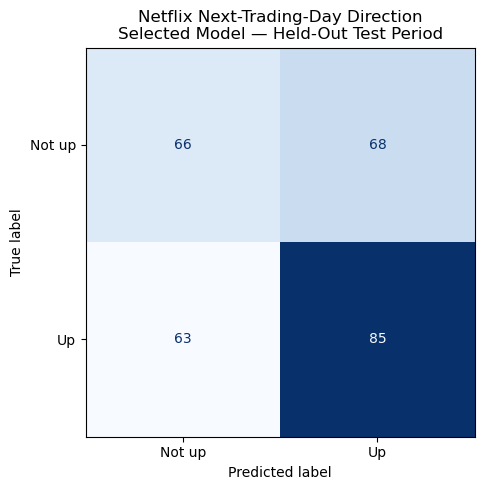

In [97]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Storing the fixed model's test outputs for later reporting
test_predictions = final_evaluation_pipeline.predict(X_test)

positive_class_index = list(
    final_evaluation_pipeline.classes_
).index(1)

test_probabilities = (
    final_evaluation_pipeline.predict_proba(X_test)[
        :, positive_class_index
    ]
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Not up", "Up"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax
)

ax.set_title(
    "Netflix Next-Trading-Day Direction\n"
    "Selected Model — Held-Out Test Period"
)

plt.tight_layout()
plt.show()

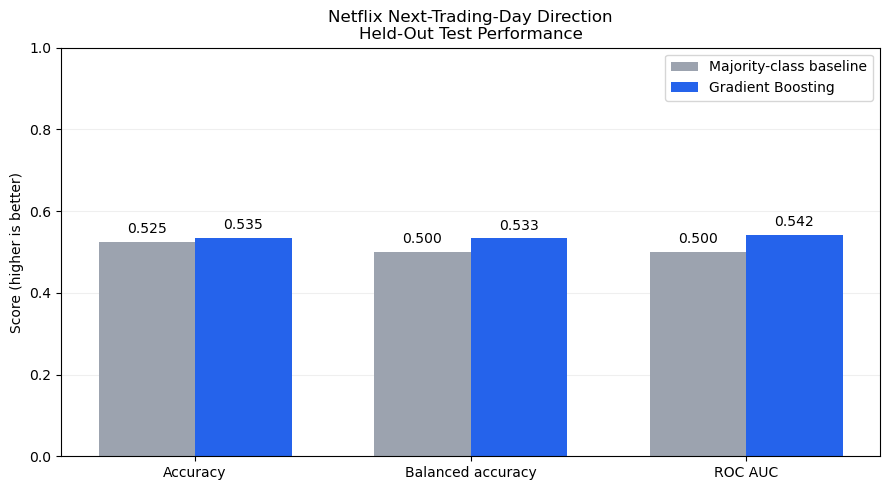

In [99]:
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    "accuracy",
    "balanced_accuracy",
    "roc_auc"
]

metric_labels = [
    "Accuracy",
    "Balanced accuracy",
    "ROC AUC"
]

comparison = final_test_results.set_index("model")

baseline_values = comparison.loc[
    "Majority-class baseline",
    metrics_to_plot
].astype(float).to_numpy()

model_values = comparison.loc[
    "Selected Gradient Boosting",
    metrics_to_plot
].astype(float).to_numpy()

x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

baseline_bars = ax.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Majority-class baseline",
    color="#9CA3AF"
)

model_bars = ax.bar(
    x + width / 2,
    model_values,
    width,
    label="Gradient Boosting",
    color="#2563EB"
)

for bars in [baseline_bars, model_bars]:
    ax.bar_label(
        bars,
        labels=[f"{bar.get_height():.3f}" for bar in bars],
        padding=4,
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Score (higher is better)")
ax.set_title(
    "Netflix Next-Trading-Day Direction\n"
    "Held-Out Test Performance"
)

ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

C:\Users\prite\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


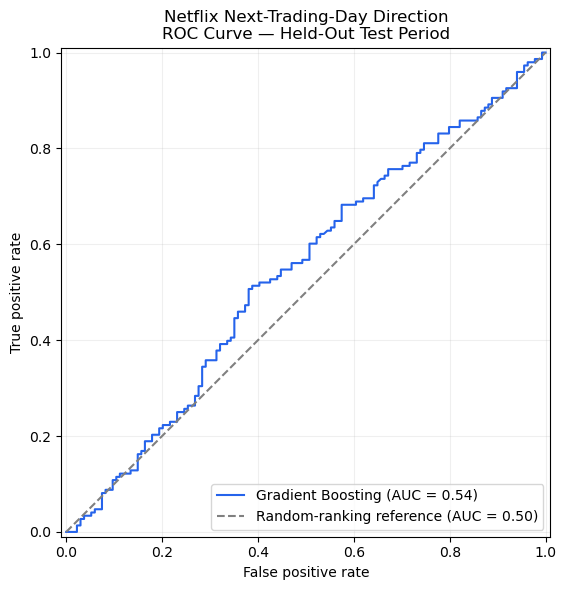

In [100]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Gradient Boosting",
    color="#2563EB",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random-ranking reference (AUC = 0.50)"
)

ax.set_title(
    "Netflix Next-Trading-Day Direction\n"
    "ROC Curve — Held-Out Test Period"
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.grid(alpha=0.2)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [ ]:
# Findings and Conclusion

# Key Findings
# The Gradient Boosting model achieved 53.55% accuracy, compared with
# 52.48% for the baseline. This represents three additional correct
# predictions across 282 test observations.

# Balanced accuracy was 53.34% and ROC AUC was 0.5416.
# These results show a modest improvement, although they do not
# demonstrate a reliable forecasting advantage.

# What I Learned
# This project helped me develop a complete workflow, from preparing
# and combining the data to engineering features, comparing models,
# tuning parameters and building a reusable pipeline.

# Comparing the model with a baseline and reviewing multiple metrics
# helped me assess its performance beyond accuracy alone.

# Were the Results Expected?
# The aim was to explore whether market data, reviews, sentiment,
# ratings and releases could help predict next day stock direction.
# The selected model improved slightly on the baseline, but the
# combined results alone do not establish whether the non-market
# features added value.

# Conclusion
# The project provides a foundation for further investigation,
# rather than a model ready for trading. Evaluation across more
# market periods and further feature-group comparisons would help
# assess whether the observed improvement is consistent.